# Western Mediterranean SSH three ways: regridded FNO, ManifoldNO (Slepian) and GeoFNO

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/geonnax/blob/main/docs/notebooks/irregular_geometry.ipynb)

One small learning task on one irregular basin, run through the three routes of the [irregular-geometry guide](../guides/irregular-geometry.md): a plain `FNO` on a regridded box with the land set to zero, a `ManifoldNO` in the basin's own Slepian basis, and a `GeoFNO` on the ocean point cloud. The task is synthetic and offline (no data download), so the whole notebook runs in a couple of minutes on a CPU. We report accuracy on ocean points, parameter counts, wall-clock time per training step and where the errors sit, with and without "clouds" (30 % of the input pixels missing).

**What you'll learn:**

1. How to build an ocean quadrature from a coastline polygon with `gauss_legendre_grid` and `spherical_polygon_mask`.
2. What each route computes, in formulas and pseudocode matched to the code below.
3. How the routes compare on accuracy, cost and coastal error, and where each one fails.

## Background

### Domain

The basin is the Western Mediterranean, longitude $[-6°, 10°]$ and latitude $[35°, 45°]$, cut by a coarse hand-drawn coastline, with the Balearic Islands (Mallorca, Menorca, Ibiza) and Corsica and Sardinia as holes. The ocean points $\mathbf{x}_n \in S^2$ and their quadrature weights $w_n$ (areas, in steradians) are the nodes of a $0.25°$ Gauss–Legendre grid that fall inside the polygon and outside every island, so that $\sum_n w_n f(\mathbf{x}_n) \approx \int_{\Omega} f\,d\Omega$ over the ocean $\Omega$.

### Task

The input is a synthetic sea-surface height (SSH) $u$, a sum of $J = 16$ smooth bumps with random centres $\mathbf{c}_j$ and amplitudes $a_j \sim \mathcal{N}(0, 1)$,

$$u(\mathbf{x}) = \sum_{j=1}^{J} a_j\, k(\mathbf{x} \cdot \mathbf{c}_j), \qquad k(t) = \sum_{l=0}^{120} b_l\, P_l(t), \qquad b_l \propto (2l + 1)\, e^{-(l/40)^2},$$

with $P_l$ the Legendre polynomials. Each bump is a zonal function a few degrees across, so $u$ is exactly band-limited to spherical-harmonic degree $120$. The output is $u$ advected for one semi-Lagrangian step by a fixed, divergence-free flow $\mathbf{v}$:

$$y(\mathbf{x}) = u\big(\mathbf{x} - \mathbf{v}(\mathbf{x})\big), \qquad \mathbf{v} = \nabla^{\perp}\psi = (-\partial_Y \psi,\ \partial_X \psi), \qquad \psi(X, Y) = \sum_{j,k=1}^{3} \alpha_{jk}\, \phi_j(X)\, \phi_k(Y).$$

The stream function uses the box-Dirichlet modes $\phi_j$ of `geonnax.basis.divfree_basis` in the chart $X = (\text{lon} - 2)/8$, $Y = (\text{lat} - 40)/5$, which maps the box onto $[-1, 1]^2$. The coefficients are $\alpha_{jk} \sim \mathcal{N}(0, 1)/\lambda_{jk}$, and the flow is rescaled so that the fastest parcel moves $0.6°$ per step. Because $u$ is a closed-form function on the whole sphere, $y$ is evaluated exactly at the departure points, with no interpolation error. The flow is divergence-free in $(\text{lon}, \text{lat})$, not in metric coordinates on the sphere, which is enough for a synthetic operator. It is not tangent to the coast, so near the coast and at the open boundary ($10°$E) some departure points lie outside the ocean: there the target depends on values no model can see, which sets an error floor at the coast for every route.

All three routes predict the increment over persistence, $\hat y = m \odot u + \mathcal{N}(\cdot)$, where $m_n \in \{0, 1\}$ marks the observed pixels. In the clear-sky case $m \equiv 1$. In the **clouds** variant, each sample drops an independent $30\,\%$ of the pixels ($m_n \sim \text{Bernoulli}(0.7)$); the models see $m \odot u$, and the loss and the scores use the observed pixels only. The score is the relative $L^2$ error on ocean points, averaged over the $64$ test fields,

$$\text{rel-}L^2 = \sqrt{\frac{\sum_n w_n m_n (\hat y_n - y_n)^2}{\sum_n w_n m_n y_n^2}},$$

and the same ratio pooled over the coastal points (within $0.3°$ of land).

### Route 1: regridded FNO (Li et al., 2021)

Regrid to a $64 \times 64$ lon/lat box $G$ by nearest neighbour ($R$), zero on land and under clouds, and stack the validity mask $m_G$ and the chart coordinates as extra channels. The `FNO` lifts, applies $L$ Fourier layers $v \mapsto \sigma\big(W v + \mathcal{F}^{-1}[R_\theta \cdot \mathcal{F} v]\big)$ over the padded box (`domain_padding=0.1` breaks the FFT's periodicity), and projects. A bilinear interpolation $B$ brings the result back to the ocean points:

$$\hat y = m \odot u + B\,\text{FNO}\big([R(m \odot u),\ m_G,\ X_G,\ Y_G]\big).$$

### Route 2: ManifoldNO in a Slepian basis (NORM; Chen et al.)

The Slepian functions of the ocean $\Omega$ at bandwidth $L$ (Simons, Dahlen & Wieczorek, 2006) are the band-limited functions $g_k$ that are best concentrated in $\Omega$, with concentrations $\lambda_k = \int_\Omega g_k^2\,d\Omega \in (0, 1)$. Roughly the Shannon number $N_\Omega = (L+1)^2 |\Omega| / 4\pi$ of them have $\lambda_k \approx 1$. A `ManifoldNO` replaces the FFT by the frozen transform $A$ (analysis) and $\Phi$ (synthesis) with $\Phi_{nk} = g_k(\mathbf{x}_n)$, and mixes channels with one matrix per mode:

$$h_\ell = \sigma\Big(\Phi \big(W_k\, (A h_{\ell-1}^\top)_k\big)_{k=1}^{K} + W h_{\ell-1}\Big), \qquad \hat y = m \odot u + Q\, h_L, \qquad h_0 = P\,[m \odot u,\ m,\ X,\ Y].$$

`BasisTransform.from_slepian` currently uses $A = \operatorname{diag}(\lambda)^{-1} \Phi^\top \operatorname{diag}(w)$, so a round trip $\Phi A$ is the projection onto the span of the $K$ Slepians. A planned change (#109) makes it the plain analysis $A = \Phi^\top \operatorname{diag}(w)$, under which a round trip multiplies mode $k$ by its concentration $\lambda_k$ (a taper). The two choices define the same model class, because a fixed per-mode factor is absorbed by the learned $W_k$; they differ only in initialisation and conditioning. With $K$ at the Shannon number, every retained $\lambda_k$ is at least about $0.48$, so the factor is at most about $2$ and this notebook does not depend on which version is installed.

### Route 3: GeoFNO (Li, Huang, Liu & Anandkumar, 2023)

A learned chart $\boldsymbol{\xi} = \varphi(\mathbf{x})$ (a box map plus an MLP residual, `deformation="mlp"`) carries the ocean points onto a latent torus. A weighted non-uniform Fourier transform encodes the field onto a uniform $32 \times 32$ latent grid, FNO blocks act there, and the truncated Fourier series is evaluated back at $\varphi(\mathbf{x})$:

$$\hat v_{\mathbf{k}} = \sum_n \tilde w_n\, (P u)_n\, e^{-2\pi i\, \mathbf{k} \cdot \boldsymbol{\xi}_n}, \qquad \tilde w_n = \frac{w_n m_n}{\sum_{n'} w_{n'} m_{n'}}, \qquad \hat y = m \odot u + \text{GeoFNO}(m \odot u;\ \mathbf{x}, \tilde w).$$

A cloudy pixel gets zero weight and contributes exactly nothing; renormalising by $\sum w m$ keeps the encoder's coefficients an unbiased quadrature over the remaining ocean. This is the only route that handles missing pixels without a refill.

### Pseudocode

```text
Route 1 (FNO, regridded)            Route 2 (ManifoldNO, Slepian)     Route 3 (GeoFNO)
g    <- R(m*u), zeros on land       h <- P [m*u, m, X, Y]   (H, N)    w~ <- w*m / sum(w*m)
x    <- [g, m_G, X_G, Y_G] (4,64,64) for layer l:                     h  <- P (m*u)          (H, N)
out  <- FNO(x)  pad 10 %, crop        a <- A h^T             (H, K)    h  <- NUFFT(h; phi(x), w~) on 32x32
yhat <- m*u + B(out)  bilinear         h <- act(Phi (W_k a_k) + W h)    h  <- FNO blocks on the torus
                                     yhat <- m*u + Q h                yhat <- m*u + Q eval(h; phi(x))
loss = sum_n w_n m_n (yhat_n - y_n)^2 / sum_n w_n m_n y_n^2, averaged over a batch; Adam, cosine decay
```

## Setup

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "geonnax @ git+https://github.com/jejjohnson/geonnax@main",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import math
import time

import equinox as eqx
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np

from geonnax import FNO, GeoFNO, ManifoldNO
from geonnax.basis import (
    divfree_basis,
    gauss_legendre_grid,
    slepian_region_basis,
    spherical_polygon_mask,
)
from geonnax.geo import lonlat_to_cartesian3d
from geonnax.layers import BasisTransform


T_START = time.perf_counter()

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,numpy,matplotlib,geonnax")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.5
IPython version      : 9.10.0

jax       : 0.10.1
equinox   : 0.13.8
numpy     : 2.4.4
matplotlib: 3.10.9
geonnax   : 0.0.8

Compiler    : GCC 11.2.0
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## Geometry

The coastline is a coarse polygon, counter-clockwise with the sea on the left (the GeoJSON convention `spherical_polygon_mask` expects). It follows the North African coast east, crosses open sea at $10°$E, and returns west along Italy, France and Spain to Gibraltar. The islands are separate counter-clockwise rings. A point is ocean if it is inside the coastline ring and outside every island ring.

In [4]:
LON0, LON1, LAT0, LAT1 = -6.0, 10.0, 35.0, 45.0

COAST = [
    (-6.0, 35.85), (-5.3, 35.9), (-4.5, 35.2), (-3.0, 35.3), (-2.0, 35.1),
    (-1.0, 35.7), (0.5, 36.0), (2.0, 36.6), (3.0, 36.8), (5.0, 36.7),
    (6.5, 37.1), (8.0, 36.9), (9.0, 37.2), (10.0, 37.3), (10.0, 44.0),
    (9.0, 44.3), (8.0, 43.9), (7.3, 43.7), (6.0, 43.1), (5.0, 43.3),
    (4.0, 43.5), (3.2, 43.2), (3.1, 42.4), (3.2, 41.9), (2.2, 41.4),
    (0.9, 41.0), (0.0, 40.0), (-0.3, 39.5), (0.2, 38.8), (-0.5, 38.3),
    (-0.8, 37.6), (-1.6, 37.3), (-2.1, 36.7), (-3.5, 36.7), (-4.4, 36.7),
    (-5.3, 36.1), (-6.0, 36.15),
]  # fmt: skip
ISLANDS = {
    "Mallorca": [(2.3, 39.6), (2.7, 39.3), (3.2, 39.3), (3.5, 39.7),
                 (3.2, 39.95), (2.6, 39.9)],
    "Menorca": [(3.8, 39.95), (4.3, 39.8), (4.4, 39.95), (3.9, 40.1)],
    "Ibiza": [(1.15, 38.9), (1.65, 38.85), (1.65, 39.15), (1.25, 39.15)],
    "Sardinia": [(8.4, 39.0), (9.0, 38.85), (9.6, 39.2), (9.8, 40.5),
                 (9.6, 41.2), (8.2, 41.0), (8.4, 40.0)],
    "Corsica": [(8.6, 41.4), (9.3, 41.4), (9.55, 42.2), (9.45, 43.0),
                (8.6, 42.4)],
}  # fmt: skip


def ocean_mask(points_xyz):
    """True for points inside the coastline ring and outside every island."""
    inside = spherical_polygon_mask(points_xyz, jnp.array(COAST))
    for ring in ISLANDS.values():
        inside &= ~spherical_polygon_mask(points_xyz, jnp.array(ring))
    return inside


# A 0.25° Gauss-Legendre grid, cut to the box, then to the ocean.
lonlat_gl, w_gl = gauss_legendre_grid(720, output="lonlat", output_unit="degrees")
lon_gl, lat_gl = lonlat_gl[:, 0], lonlat_gl[:, 1]
box = (lon_gl >= LON0) & (lon_gl < LON1) & (lat_gl >= LAT0) & (lat_gl <= LAT1)
lonlat_box, w_box = lonlat_gl[box], w_gl[box]
xyz_box = lonlat_to_cartesian3d(lonlat_box, input_unit="degrees")
sea = ocean_mask(xyz_box)

lonlat, xyz, w = lonlat_box[sea], xyz_box[sea], w_box[sea]  # (N, 2) (N, 3) (N,)
N = lonlat.shape[0]

# Great-circle distance (degrees) from each ocean point to the nearest land point.
cos_gap = jnp.max(xyz @ xyz_box[~sea].T, axis=1)
dist_land = jnp.rad2deg(jnp.arccos(jnp.clip(cos_gap, -1.0, 1.0)))  # (N,)
COAST_BAND = 0.3
coastal = dist_land < COAST_BAND
area_frac = float(w.sum()) / (4 * math.pi)
print(f"{N} ocean points, {int(coastal.sum())} within {COAST_BAND}° of land")
print(f"ocean area: {area_frac:.5f} of the sphere")

1023 ocean points, 197 within 0.3° of land
ocean area: 0.00120 of the sphere


## Data

`legendre_series` sums $\sum_l c_l P_l(t)$ with Bonnet's recursion $(l+1)P_{l+1} = (2l+1)\,t\,P_l - l\,P_{l-1}$, which is stable for $|t| \le 1$. It gives the bump profile $k$ here and the band-limited reproducing kernel in the next section.

In [5]:
def legendre_series(t, coeffs):
    """Sum_l coeffs[l] P_l(t) by Bonnet's recursion, elementwise in t."""

    def step(carry, inputs):
        p_prev, p, acc = carry
        ell, c = inputs
        p_next = ((2 * ell + 1) * t * p - ell * p_prev) / (ell + 1)
        return (p, p_next, acc + c * p_next), None

    init = (jnp.ones_like(t), t, coeffs[0] + coeffs[1] * t)
    ells = jnp.arange(1, coeffs.shape[0] - 1, dtype=t.dtype)
    (_, _, acc), _ = jax.lax.scan(step, init, (ells, coeffs[2:]))
    return acc


L_DATA, ELL0, J = 120, 40.0, 16
ell = jnp.arange(L_DATA + 1, dtype=jnp.float32)
bump_coeffs = (2 * ell + 1) * jnp.exp(-((ell / ELL0) ** 2))
bump_coeffs = bump_coeffs / bump_coeffs.sum()  # k(1) = 1 at the bump centre


def sample_bumps(key, n):
    """Centres (n, J, 3) and amplitudes (n, J), over a box wider than the basin."""
    k_lon, k_lat, k_amp = jr.split(key, 3)
    lon = jr.uniform(k_lon, (n, J), minval=LON0 - 2.0, maxval=LON1 + 2.0)
    lat = jr.uniform(k_lat, (n, J), minval=LAT0 - 2.0, maxval=LAT1 + 2.0)
    lonlat_c = jnp.stack([lon, lat], -1).reshape(-1, 2)
    centres = lonlat_to_cartesian3d(lonlat_c, input_unit="degrees")
    return centres.reshape(n, J, 3), jr.normal(k_amp, (n, J))


@jax.jit
def ssh_at(points_xyz, centres, amps):
    """One field u at (P, 3) points -> (P,)."""
    return legendre_series(points_xyz @ centres.T, bump_coeffs) @ amps


def chart(ll):
    """(lon, lat) in degrees -> (X, Y) in [-1, 1]^2 over the box."""
    return jnp.stack([(ll[:, 0] - 2.0) / 8.0, (ll[:, 1] - 40.0) / 5.0], -1)


# Fixed divergence-free flow: skew gradients of box-Dirichlet stream functions.
atoms, lam = divfree_basis(chart(lonlat), 3, 1.0)  # (N, 9, 2), (9,)
alpha = jr.normal(jr.key(7), (9,)) / lam
vel = jnp.einsum("nmc,m->nc", atoms, alpha) * jnp.array([8.0, 5.0])  # deg / step
MAX_SHIFT = 0.6  # degrees moved by the fastest parcel in one step
vel = vel * MAX_SHIFT / jnp.max(jnp.linalg.norm(vel, axis=1))
departure = lonlat_to_cartesian3d(lonlat - vel, input_unit="degrees")  # (N, 3)

N_TRAIN, N_TEST = 256, 64
centres, amps = sample_bumps(jr.key(0), N_TRAIN + N_TEST)
u_all = jax.vmap(ssh_at, in_axes=(None, 0, 0))(xyz, centres, amps)  # (S, N)
y_all = jax.vmap(ssh_at, in_axes=(None, 0, 0))(departure, centres, amps)
scale = u_all[:N_TRAIN].std()
u_train, u_test = u_all[:N_TRAIN] / scale, u_all[N_TRAIN:] / scale
y_train, y_test = y_all[:N_TRAIN] / scale, y_all[N_TRAIN:] / scale

# Clouds: an independent 30 % pixel dropout per sample (1 = observed).
P_CLOUD = 0.3
keep = (jr.uniform(jr.key(1), u_all.shape) > P_CLOUD).astype(jnp.float32)
keep_train, keep_test = keep[:N_TRAIN], keep[N_TRAIN:]
print(f"train {u_train.shape}, test {u_test.shape} (fields x ocean points)")

train (256, 1023), test (64, 1023) (fields x ocean points)


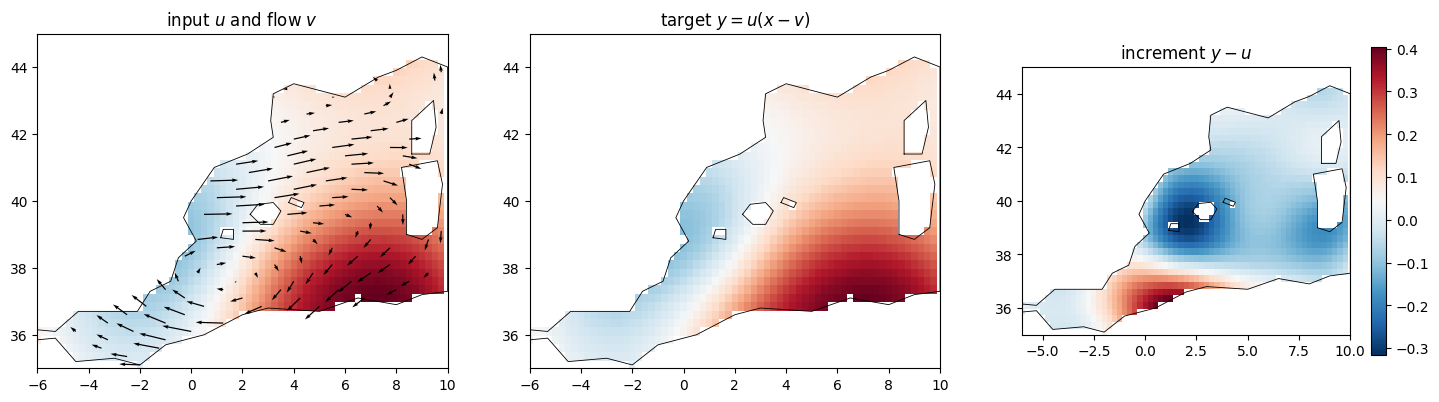

In [6]:
def draw_coast(ax):
    for ring in [COAST, *ISLANDS.values()]:
        r = np.array([*ring, ring[0]])
        ax.plot(r[:, 0], r[:, 1], "k-", lw=0.6)
    ax.set_xlim(LON0, LON1)
    ax.set_ylim(LAT0, LAT1)
    ax.set_aspect(1 / math.cos(math.radians(40.0)))


# The ocean points sit on a (lat x lon) sub-grid of the Gauss-Legendre grid.
lon_axis = np.unique(np.asarray(lonlat[:, 0]))
lat_axis = np.unique(np.asarray(lonlat[:, 1]))
pix_i = np.searchsorted(lat_axis, np.asarray(lonlat[:, 1]))
pix_j = np.searchsorted(lon_axis, np.asarray(lonlat[:, 0]))


def show(ax, values, title, **kw):
    img = np.full((lat_axis.size, lon_axis.size), np.nan)
    img[pix_i, pix_j] = np.asarray(values)
    mesh = ax.pcolormesh(lon_axis, lat_axis, img, shading="nearest", **kw)
    draw_coast(ax)
    ax.set_title(title)
    return mesh


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
vmax = float(jnp.abs(u_test[0]).max())
show(axes[0], u_test[0], "input $u$ and flow $v$", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
q = slice(None, None, 9)
axes[0].quiver(lonlat[q, 0], lonlat[q, 1], vel[q, 0], vel[q, 1], scale=8, width=0.003)
show(axes[1], y_test[0], "target $y = u(x - v)$", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
sc = show(axes[2], y_test[0] - u_test[0], "increment $y - u$", cmap="RdBu_r")
plt.colorbar(sc, ax=axes[2], shrink=0.8)
plt.show()

## Route 2's basis: Slepian functions of the basin

The ocean covers about $0.12\,\%$ of the sphere, so a Shannon number of about $27$ needs bandwidth $L = 150$. `slepian_region_basis` builds the $(L+1)^2 \times (L+1)^2$ concentration matrix $D = Y^\top \operatorname{diag}(w)\, Y$ from `real_spherical_harmonics`. At $L = 150$ that is a $22\,801 \times 22\,801$ eigenproblem, and in float32 `real_spherical_harmonics` overflows above degree $28$. We therefore solve the same eigenproblem in its $N \times N$ dual form. Write $W = \operatorname{diag}(w)$ and $K = Y Y^\top$. By the addition theorem, $K_{nm} = \sum_{l \le L} \frac{2l+1}{4\pi} P_l(\mathbf{x}_n \cdot \mathbf{x}_m)$ is the band-limited reproducing kernel. The matrix $G = W^{1/2} K W^{1/2}$ has the same nonzero eigenvalues $\lambda_k$ as $D$. If $G v_k = \lambda_k v_k$, the Slepian function and its values at the quadrature points are

$$g_k(\mathbf{x}) = \lambda_k^{-1/2} \sum_n K(\mathbf{x}, \mathbf{x}_n)\, \sqrt{w_n}\, v_{nk}, \qquad g_k(\mathbf{x}_n) = \sqrt{\lambda_k / w_n}\; v_{nk},$$

so $\int_{S^2} g_k^2 = 1$ and $\sum_n w_n g_k(\mathbf{x}_n)^2 = \lambda_k$. The cost is $O(N^2 L)$ to fill $G$ plus an $N \times N$ `eigh`. `KernelSlepians` below has the `evaluate` / `num_modes` interface that `BasisTransform.from_slepian` reads. First we check that it reproduces `slepian_region_basis` at a degree the library handles in float32.

In [7]:
def kernel_coeffs(l_max):
    """Legendre coefficients (2l + 1) / 4 pi of the band-limited kernel."""
    deg = jnp.arange(l_max + 1, dtype=jnp.float32)
    return (2 * deg + 1) / (4 * math.pi)


class KernelSlepians(eqx.Module):
    """Region Slepian functions through the band-limited reproducing kernel."""

    l_max: int = eqx.field(static=True)
    nodes: jax.Array  # (Q, 3) region quadrature points
    loadings: jax.Array  # (Q, K) sqrt(w) v_k / sqrt(lambda_k)
    eigenvalues: jax.Array  # (K,) concentrations, decreasing

    @classmethod
    def build(cls, l_max, points_xyz, weights, n_modes=None):
        sw = jnp.sqrt(weights)
        kernel = legendre_series(points_xyz @ points_xyz.T, kernel_coeffs(l_max))
        vals, vecs = jnp.linalg.eigh(sw[:, None] * kernel * sw[None, :])
        vals, vecs = vals[::-1], vecs[:, ::-1]
        if n_modes is None:
            n_modes = round(float(vals.sum()))  # Shannon number, trace of G
        vals, vecs = vals[:n_modes], vecs[:, :n_modes]
        loadings = sw[:, None] * vecs / jnp.sqrt(vals)[None, :]
        return cls(l_max=l_max, nodes=points_xyz, loadings=loadings, eigenvalues=vals)

    @property
    def num_modes(self):
        return int(self.eigenvalues.shape[0])

    def truncate(self, n_modes):
        return eqx.tree_at(
            lambda s: (s.loadings, s.eigenvalues),
            self,
            (self.loadings[:, :n_modes], self.eigenvalues[:n_modes]),
        )

    def evaluate(self, unit_xyz):
        k = legendre_series(unit_xyz @ self.nodes.T, kernel_coeffs(self.l_max))
        return k @ self.loadings  # (P, K)


lib = slepian_region_basis(6, xyz, w, n_modes=3)
ours = KernelSlepians.build(6, xyz, w, n_modes=3)
print("slepian_region_basis(6):", np.asarray(lib.eigenvalues).round(5))
print("KernelSlepians(6):      ", np.asarray(ours.eigenvalues).round(5))

slepian_region_basis(6): [0.05597 0.0021  0.00053]
KernelSlepians(6):       [0.05597 0.0021  0.00053]


At $L = 150$ the Shannon number is $27$. Keeping more modes captures more of the input. The table below shows how much of the test inputs the $K$-mode projection misses, and the concentration $\lambda_K$ of the last mode kept. Past the Shannon number $\lambda_K$ falls fast: the current `from_slepian` would amplify mode $K$ by $1/\lambda_K$, and the plain analysis of #109 would taper it by $\lambda_K$. We keep $K = N_\Omega$. The pointwise skip $W h$ of every block still carries the full-resolution field, so the spectral path only has to carry the large scales.

Shannon number at L = 150: 27
   K  lambda_K  missed (rel. L2 of the test inputs)


  27     0.484  0.267


  40     0.142  0.117


  60     0.009  0.020


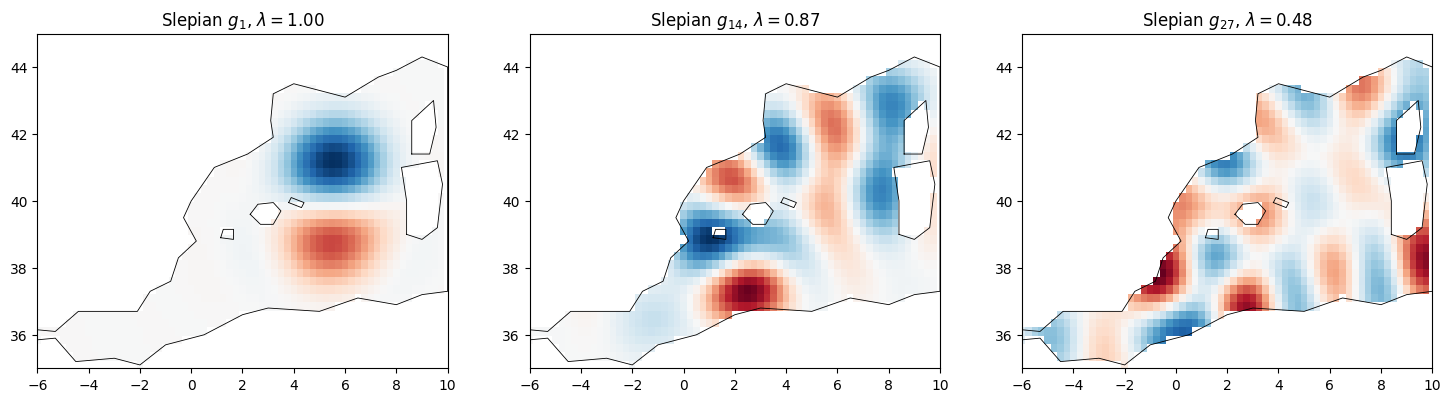

In [8]:
L_SLEP = 150
slep_all = KernelSlepians.build(L_SLEP, xyz, w, n_modes=60)
shannon = round((L_SLEP + 1) ** 2 * area_frac)
print(f"Shannon number at L = {L_SLEP}: {shannon}")
print("   K  lambda_K  missed (rel. L2 of the test inputs)")
sqrt_w = jnp.sqrt(w)
for n_keep in (shannon, 40, 60):
    sub = slep_all.truncate(n_keep)
    tr = BasisTransform.from_slepian(sub, xyz, w)
    resid = tr.inverse(tr.forward(u_test)) - u_test
    miss = jnp.linalg.norm(resid * sqrt_w) / jnp.linalg.norm(u_test * sqrt_w)
    print(f"{n_keep:4d}  {float(sub.eigenvalues[-1]):8.3f}  {float(miss):.3f}")

slep = slep_all.truncate(shannon)
transform = BasisTransform.from_slepian(slep, xyz, w)

phi = slep.evaluate(xyz)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, k in zip(axes, (0, shannon // 2, shannon - 1), strict=True):
    lim = float(jnp.abs(phi[:, k]).max())
    lam_k = float(slep.eigenvalues[k])
    title = f"Slepian $g_{{{k + 1}}}$, $\\lambda = {lam_k:.2f}$"
    show(ax, phi[:, k], title, cmap="RdBu_r", vmin=-lim, vmax=lim)
plt.show()

## The three routes

Each `*_apply` maps one input field $u$ (shape `(N,)`) and its observation mask $m$ to a prediction at the $N$ ocean points. Routes 1 and 2 see the cloudy pixels as zeros plus a mask channel (a zero refill); Route 3 gives them zero quadrature weight.

In [9]:
# Route 1: a 64 x 64 lon/lat box, nearest-neighbour in, bilinear out.
NG = 64
glon = LON0 + (jnp.arange(NG) + 0.5) * (LON1 - LON0) / NG
glat = LAT0 + (jnp.arange(NG) + 0.5) * (LAT1 - LAT0) / NG
GLAT, GLON = jnp.meshgrid(glat, glon, indexing="ij")
grid_lonlat = jnp.stack([GLON.ravel(), GLAT.ravel()], -1)
grid_xyz = lonlat_to_cartesian3d(grid_lonlat, input_unit="degrees")
grid_sea = ocean_mask(grid_xyz).astype(jnp.float32)  # (NG * NG,)
nearest = jnp.argmax(grid_xyz @ xyz.T, axis=1)  # nearest ocean point of each cell
coords_grid = chart(grid_lonlat).T.reshape(2, NG, NG)
coords_pts = chart(lonlat).T  # (2, N)
print(f"{int(grid_sea.sum())} of {NG * NG} grid cells are ocean")

# Bilinear weights from the grid back to the ocean points, computed once.
rows = (lonlat[:, 1] - LAT0) / ((LAT1 - LAT0) / NG) - 0.5
cols = (lonlat[:, 0] - LON0) / ((LON1 - LON0) / NG) - 0.5
r0 = jnp.clip(jnp.floor(rows), 0, NG - 2).astype(jnp.int32)
c0 = jnp.clip(jnp.floor(cols), 0, NG - 2).astype(jnp.int32)
fr, fc = jnp.clip(rows - r0, 0.0, 1.0), jnp.clip(cols - c0, 0.0, 1.0)
corner_idx = jnp.stack(
    [r0 * NG + c0, r0 * NG + c0 + 1, (r0 + 1) * NG + c0, (r0 + 1) * NG + c0 + 1], -1
)  # (N, 4)
corner_w = jnp.stack(
    [(1 - fr) * (1 - fc), (1 - fr) * fc, fr * (1 - fc), fr * fc], -1
)  # (N, 4)


def fno_apply(model, u, m):
    seen = grid_sea * m[nearest]  # zero on land and under cloud
    g = (u * m)[nearest] * seen
    x = jnp.concatenate([g.reshape(1, NG, NG), seen.reshape(1, NG, NG), coords_grid])
    out = model(x)[0].ravel()  # (NG * NG,)
    return u * m + jnp.sum(out[corner_idx] * corner_w, axis=-1)


# Route 2: the basin's Slepian basis.
def mno_apply(model, u, m):
    x = jnp.concatenate([(u * m)[None], m[None], coords_pts])  # (4, N)
    return u * m + model(x)[0]


# Route 3: the ocean point cloud, cloudy pixels at zero weight.
def geo_apply(model, u, m):
    wm = w * m
    return u * m + model((u * m)[None], lonlat, wm / wm.sum())[0]

1657 of 4096 grid cells are ocean


## Training

Adam with a cosine-decayed step size, written out in a few lines because optax is not a geonnax dependency. Every route trains for the same $400$ steps of $8$ fields from the same seed, and the step time is the median wall-clock time of a jitted step, which includes the forward and backward passes, after compilation.

In [10]:
def adam(lr, total, b1=0.9, b2=0.999, eps=1e-8):
    def init(params):
        zeros = jax.tree.map(jnp.zeros_like, params)
        return zeros, zeros, jnp.zeros((), jnp.int32)

    def update(grads, state, params):
        mu, nu, t = state
        t = t + 1
        mu = jax.tree.map(lambda a, g: b1 * a + (1 - b1) * g, mu, grads)
        nu = jax.tree.map(lambda a, g: b2 * a + (1 - b2) * g * g, nu, grads)
        lr_t = lr * 0.5 * (1 + jnp.cos(jnp.pi * t / total))
        c1, c2 = 1 - b1**t, 1 - b2**t
        params = jax.tree.map(
            lambda p, a, b: p - lr_t * (a / c1) / (jnp.sqrt(b / c2) + eps),
            params, mu, nu,
        )  # fmt: skip
        return params, (mu, nu, t)

    return init, update


def train(model, apply, keep_tr, *, key, steps=400, batch=8, lr=3e-3):
    params, static = eqx.partition(model, eqx.is_inexact_array)
    opt_init, opt_update = adam(lr, steps)
    state = opt_init(params)

    def loss_fn(p, u, y, m):
        net = eqx.combine(p, static)
        pred = jax.vmap(lambda a, b: apply(net, a, b))(u, m)
        wm = w * m  # score the observed pixels only
        return jnp.mean(jnp.sum(wm * (pred - y) ** 2, 1) / jnp.sum(wm * y**2, 1))

    @jax.jit
    def step(p, s, idx):
        args = (u_train[idx], y_train[idx], keep_tr[idx])
        loss, g = jax.value_and_grad(loss_fn)(p, *args)
        p, s = opt_update(g, s, p)
        return p, s, loss

    times = []
    for i in range(steps):
        idx = jr.choice(jr.fold_in(key, i), N_TRAIN, (batch,), replace=False)
        t0 = time.perf_counter()
        params, state, loss = step(params, state, idx)
        loss.block_until_ready()
        times.append(time.perf_counter() - t0)
    return eqx.combine(params, static), 1e3 * float(np.median(times[5:]))


def scores(pred, m):
    """Mean relative L2, pooled coastal relative L2, per-point mean |error|."""
    err = pred - y_test
    wm = w * m
    rel = jnp.sqrt(jnp.sum(wm * err**2, 1) / jnp.sum(wm * y_test**2, 1))
    cw = wm * coastal
    rel_coast = jnp.sqrt(jnp.sum(cw * err**2) / jnp.sum(cw * y_test**2))
    emap = jnp.sum(m * jnp.abs(err), 0) / jnp.sum(m, 0)
    return float(rel.mean()), float(rel_coast), emap


def n_params(model):
    """Trainable parameters (the frozen Slepian tables are not counted)."""
    leaves = eqx.filter(model, eqx.is_inexact_array)
    if isinstance(model, ManifoldNO):
        leaves = eqx.tree_at(lambda net: net.transform, leaves, None)
    return sum(x.size for x in jax.tree.leaves(leaves))

All three use hidden width $12$ and $4$ layers. The FNO keeps $12 \times 12$ Fourier modes per corner on the padded $64 \times 64$ box. The GeoFNO keeps $12 \times 12$ modes on a $32 \times 32$ latent grid. The ManifoldNO keeps the $27$ Slepian modes.

In [11]:
H, LAYERS = 12, 4
routes = {
    "FNO (regridded)": (
        lambda k: FNO.init(4, 1, (12, 12), key=k, hidden_channels=H,
                           n_layers=LAYERS, domain_padding=0.1),
        fno_apply,
    ),
    "ManifoldNO (Slepian)": (
        lambda k: ManifoldNO.init(4, 1, transform, key=k, hidden_channels=H,
                                  n_layers=LAYERS),
        mno_apply,
    ),
    "GeoFNO": (
        lambda k: GeoFNO.init(1, 1, (12, 12), (32, 32), key=k,
                              lower=(LON0, LAT0), upper=(LON1, LAT1),
                              hidden_channels=H, n_layers=LAYERS,
                              deformation="mlp"),
        geo_apply,
    ),
}  # fmt: skip
variants = {
    "clear": (jnp.ones_like(keep_train), jnp.ones_like(keep_test)),
    "30% clouds": (keep_train, keep_test),
}

table, err_maps = [], {}
for variant, (k_tr, k_te) in variants.items():
    rel, rel_coast, _ = scores(u_test * k_te, k_te)
    table.append(("persistence (y = u)", variant, 0, float("nan"), rel, rel_coast))
    for name, (build, apply) in routes.items():
        model, ms = train(build(jr.key(42)), apply, k_tr, key=jr.key(3))
        predict = jax.jit(jax.vmap(lambda a, b, f=apply, net=model: f(net, a, b)))
        rel, rel_coast, emap = scores(predict(u_test, k_te), k_te)
        err_maps[(name, variant)] = emap
        table.append((name, variant, n_params(model), ms, rel, rel_coast))

header = ("route", "variant", "params", "ms/step", "rel-L2", "coastal")
print("{:22s} {:11s} {:>8s} {:>8s} {:>7s} {:>8s}".format(*header))
for name, variant, n_p, ms, rel, rel_coast in table:
    n_txt = f"{n_p:8d}" if n_p else f"{'-':>8s}"
    ms_txt = f"{ms:8.1f}" if n_p else f"{'-':>8s}"
    print(f"{name:22s} {variant:11s} {n_txt} {ms_txt} {rel:7.3f} {rel_coast:8.3f}")

route                  variant       params  ms/step  rel-L2  coastal
persistence (y = u)    clear              -        -   0.091    0.088
FNO (regridded)        clear         332677     71.7   0.025    0.030
ManifoldNO (Slepian)   clear          16453      7.0   0.051    0.057
GeoFNO                 clear         386759     29.7   0.033    0.038
persistence (y = u)    30% clouds         -        -   0.091    0.088
FNO (regridded)        30% clouds    332677     71.9   0.037    0.041
ManifoldNO (Slepian)   30% clouds     16453      6.8   0.055    0.060
GeoFNO                 30% clouds    386759     30.2   0.044    0.049


## Where the errors are

The maps show the mean absolute error per ocean point over the test fields (clear sky), on one colour scale. The curves bin the error by distance to land, normalised by the target's size in the same bin, for both variants.

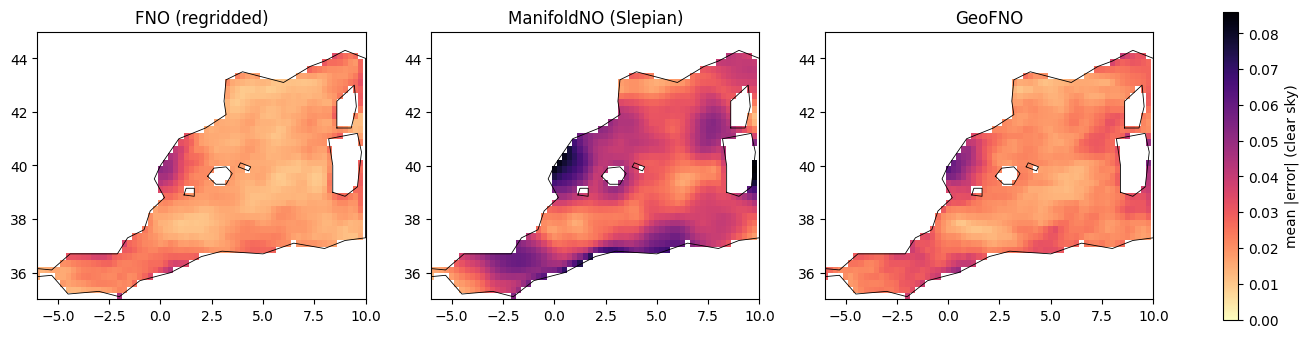

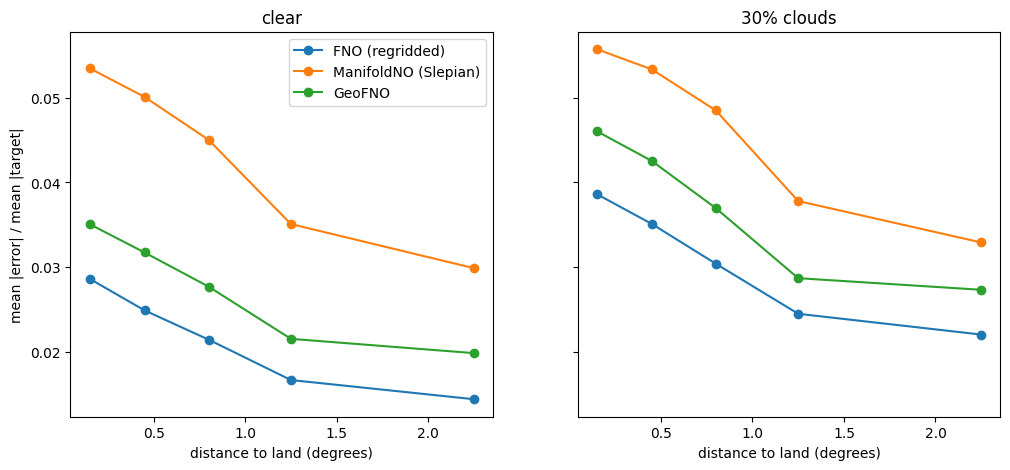

total runtime: 141 s


In [12]:
names = list(routes)
emax = max(float(err_maps[(n, "clear")].max()) for n in names)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, names, strict=True):
    sc = show(ax, err_maps[(name, "clear")], name, cmap="magma_r", vmin=0, vmax=emax)
plt.colorbar(sc, ax=axes, shrink=0.8, label="mean |error| (clear sky)")
plt.show()

bins = np.array([0.0, 0.3, 0.6, 1.0, 1.5, 3.0])
centre = 0.5 * (bins[1:] + bins[:-1])
band = np.digitize(np.asarray(dist_land), bins) - 1
y_abs = np.mean(np.abs(np.asarray(y_test)), 0)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, variant in zip(axes, variants, strict=True):
    for i, name in enumerate(names):
        e = np.asarray(err_maps[(name, variant)])
        ratio = [e[band == b].mean() / y_abs[band == b].mean() for b in range(5)]
        ax.plot(centre, ratio, "o-", color=f"C{i}", label=name)
    ax.set_xlabel("distance to land (degrees)")
    ax.set_title(variant)
axes[0].set_ylabel("mean |error| / mean |target|")
axes[0].legend()
plt.show()
print(f"total runtime: {time.perf_counter() - T_START:.0f} s")

## Results and failure modes

### What the table says

- **Clear sky.** All three routes beat persistence ($0.091$). The regridded FNO is the most accurate ($0.025$), then GeoFNO ($0.033$), then ManifoldNO ($0.051$).
- **Cost.** ManifoldNO is by far the cheapest: about $16$k trainable parameters (twenty times fewer than the others) and about $7$ ms per step, against about $31$ ms for GeoFNO and $72$ ms for the FNO. The FNO pays for its box: only $1657$ of the $4096$ cells are ocean, so most of its FFT work is on land, and the $64 \times 64$ grid alone has four times as many nodes as there are ocean points (before the $10\,\%$ padding).
- **Clouds.** Every route loses at most about one point. The FNO with a zero refill and a mask channel stays ahead of GeoFNO ($0.037$ against $0.044$), so GeoFNO's native handling of missing pixels did not buy accuracy here. Independent $30\,\%$ dropout of $0.25°$ pixels, in fields a few degrees across, is easy to refill, and the FNO learns the refill from the mask channel. Spatially correlated clouds, with whole patches missing, would be a harder and fairer test; this notebook does not run it. ManifoldNO degrades least ($0.051 \to 0.055$): its spectral path only carries large scales, which scattered gaps barely change.
- **Coast.** Within $0.3°$ of land the error per unit of signal is about twice its open-water value, and the curves have the same shape for all three routes. The shared cause is the task itself. The flow is not tangent to the coast, so at inflow points the target reads values from over land that no route can see. At this resolution there is no coastal penalty specific to the FNO.

### Failure modes

**Route 1, regridded FNO.**

- *Leakage across the coast.* The zeros on land enter every FFT, so each Fourier layer mixes land cells into the coastal ocean cells, and the bilinear read-back mixes the outputs of land cells into the coastal points. The network has to learn to undo this from the mask channel. Here it did. With narrower passages than this grid resolves (the Strait of Gibraltar is barely a pixel wide here), or without the mask channel, nothing guarantees it.
- *The grid is the box, not the basin.* Compute and memory scale with the bounding box, most of which is land here.
- *Two interpolations.* Nearest neighbour in and bilinear out each add sub-pixel error that the other routes avoid.

**Route 2, ManifoldNO in a Slepian basis.**

- *A small basin needs a high bandwidth.* At $0.12\,\%$ of the sphere, $27$ well-concentrated modes need $L = 150$. `slepian_region_basis` cannot reach this: its concentration matrix is $(L+1)^2 \times (L+1)^2$, and `real_spherical_harmonics` overflows in float32 above degree $28$. The kernel (dual) form used here costs $O(N^2 L)$ and one $N \times N$ `eigh`.
- *Shannon truncation.* The $27$ modes miss $27\,\%$ of the input (the table above). Keeping more modes means keeping $\lambda_K \ll 1$, where the choice of analysis normalisation (#109) starts to matter.
- *One mixing matrix per mode.* Each spectral layer acts on each Slepian mode separately. Advection by a non-uniform flow couples modes, which the network can only reach through its nonlinearities and the coordinate channels. This is a plausible reason why it is the least accurate here.
- *Tied to the geometry.* The weights belong to this basin's modes. Another coastline or another sampling needs a new basis and retraining.

**Route 3, GeoFNO.**

- *Latent band limit.* The output is a truncated Fourier series of $12 \times 12$ modes in the chart, followed by a pointwise projection. There is no pointwise path from input to output, so detail finer than the latent modes cannot pass through the operator; here the persistence term $m \odot u$ carries it.
- *Encoder cost.* Each example builds an $N \times |\mathcal{K}|$ table of complex exponentials (here $1023 \times 288$), which dominates memory as $N$ grows.
- *Unused flexibility.* The geometry is the same for every sample, so the learned chart's ability to follow per-sample shapes is not exercised here.

**All routes.** This is one seed, $400$ steps, width $12$ and a coarse coastline. Gaps of about one point or less between routes should not be over-read.

### Which route to pick

- A fixed basin on a regular grid, with clouds as a mask: the regridded FNO with a mask channel is a strong and simple baseline.
- A fixed geometry, smooth large-scale fields, and a tight parameter or compute budget: ManifoldNO.
- A geometry or sampling that changes from sample to sample (swaths, tracks, varying sets of valid points): GeoFNO, the one route that reads a point cloud without a grid.

## References

- Z. Li, N. Kovachki, K. Azizzadenesheli, B. Liu, K. Bhattacharya, A. Stuart, A. Anandkumar. *Fourier Neural Operator for Parametric Partial Differential Equations.* ICLR 2021. [arXiv:2010.08895](https://arxiv.org/abs/2010.08895).
- Z. Li, D. Z. Huang, B. Liu, A. Anandkumar. *Fourier Neural Operator with Learned Deformations for PDEs on General Geometries.* Journal of Machine Learning Research 24(388), 2023. [arXiv:2207.05209](https://arxiv.org/abs/2207.05209).
- G. Chen, X. Liu, Q. Meng, L. Chen, C. Liu, Y. Li. *Learning Neural Operators on Riemannian Manifolds.* [arXiv:2302.08166](https://arxiv.org/abs/2302.08166).
- F. J. Simons, F. A. Dahlen, M. A. Wieczorek. *Spatiospectral Concentration on a Sphere.* SIAM Review 48(3), 504–536, 2006. [doi:10.1137/S0036144504445765](https://doi.org/10.1137/S0036144504445765).